In [1]:
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.mask import mask
from rasterio.warp import reproject, Resampling
from pystac_client import Client
from concurrent.futures import ThreadPoolExecutor

# Hide harmless "divide by zero" messages; our -1..1 sanity check removes those pixels anyway
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Seward County border (degrees for searching, metres for clipping)
counties = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip")
seward = counties[(counties["STATEFP"] == "31") & (counties["NAME"] == "Seward")]
seward_utm = seward.to_crs("EPSG:32614")

catalog = Client.open("https://earth-search.aws.element84.com/v1")
print("Ready. Seward area (km²):", round(seward_utm.area.iloc[0] / 1e6, 1))

Ready. Seward area (km²): 1491.3


In [2]:
search = catalog.search(
    collections=["sentinel-2-l2a"],
    intersects=seward.to_crs("EPSG:4326").geometry.iloc[0],   # images touching Seward's shape
    datetime="2022-05-01/2022-10-31",
    query={"eo:cloud_cover": {"lt": 80}},                      # skip almost fully cloudy tiles
)
items = [it for it in search.items() if "14TPL" in it.id]      # our tile only

# Keep one image per date: the one with the newest processing version
best = {}
for it in items:
    day = it.datetime.date()
    version = float(it.properties["s2:processing_baseline"])
    if day not in best or version > float(best[day].properties["s2:processing_baseline"]):
        best[day] = it

print("Images found:", len(items), "| unique dates:", len(best))

Images found: 56 | unique dates: 55


In [3]:
KEEP = [4, 5, 6]          # SCL: vegetation, bare soil, water
MIN_CLEAR = 0.30          # skip dates with less than 30% clear pixels

def read_band(item, band, county):
    """Read one band inside the county at 20 m (overview level 0), as reflectance."""
    asset = item.assets[band]
    label = asset.extra_fields["raster:bands"][0]
    with rasterio.open(asset.href, overview_level=0) as src:      # the half-size (20 m) version
        data, transform = mask(src, county.geometry, crop=True)
    data = data[0].astype("float32")
    data[data == label["nodata"]] = np.nan
    offset = 0.0 if item.properties.get("earthsearch:boa_offset_applied") else label["offset"]
    return data * label["scale"] + offset, transform

def summarise_date(item):
    """Cloud-masked county median NDVI and EVI for one image."""
    red, transform = read_band(item, "red", seward_utm)
    inside = ~np.isnan(red)

    # Cloud labels onto the same grid
    scl = np.zeros(red.shape, dtype="uint8")
    with rasterio.open(item.assets["scl"].href) as src:
        reproject(rasterio.band(src, 1), scl,
                  src_transform=src.transform, src_crs=src.crs,
                  dst_transform=transform, dst_crs=src.crs,
                  resampling=Resampling.nearest)
    good = np.isin(scl, KEEP) & inside
    clear = good.sum() / inside.sum()

    row = {"date": pd.Timestamp(item.datetime.date()), "item": item.id,
           "clear": round(float(clear), 3), "ndvi": np.nan, "evi": np.nan}
    if clear < MIN_CLEAR:
        return row                                  # too cloudy: keep the row, leave values blank

    nir, _ = read_band(item, "nir", seward_utm)
    blue, _ = read_band(item, "blue", seward_utm)
    ndvi = np.where(good, (nir - red) / (nir + red), np.nan)
    evi = np.where(good, 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 1), np.nan)
    evi[(evi < -1) | (evi > 1) | ~np.isfinite(evi)] = np.nan     # sanity check

    row["ndvi"] = round(float(np.nanmedian(ndvi)), 3)
    row["evi"] = round(float(np.nanmedian(evi)), 3)
    return row

# Run 8 dates at a time
with ThreadPoolExecutor(max_workers=8) as pool:
    rows = list(pool.map(summarise_date, [best[d] for d in sorted(best)]))

ts = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
print("Dates used:", ts["ndvi"].notna().sum(), "| skipped (too cloudy):", ts["ndvi"].isna().sum())
ts

/Users/iffat180/Desktop/AgroScope/.venv/lib/python3.12/site-packages/rasterio/features.py:381: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  _rasterize(


Dates used: 46 | skipped (too cloudy): 9


,date,item,clear,ndvi,evi
0,2022-05-07,S2A_14TPL_20220507_0_L2A,0.561,0.197,0.119
1,2022-05-09,S2B_14TPL_20220509_0_L2A,0.999,0.183,0.137
2,2022-05-12,S2B_14TPL_20220512_0_L2A,0.622,0.164,0.124
3,2022-05-14,S2A_14TPL_20220514_0_L2A,0.782,0.180,0.132
4,2022-05-19,S2B_14TPL_20220519_0_L2A,0.765,0.193,0.148
5,2022-05-22,S2B_14TPL_20220522_0_L2A,0.998,0.213,0.154
6,2022-05-27,S2A_14TPL_20220527_0_L2A,0.976,0.227,0.129
7,2022-06-03,S2A_14TPL_20220603_0_L2A,0.991,0.243,0.189
8,2022-06-06,S2A_14TPL_20220606_0_L2A,0.226,NaN,NaN
9,2022-06-08,S2B_14TPL_20220608_0_L2A,0.960,0.366,0.250


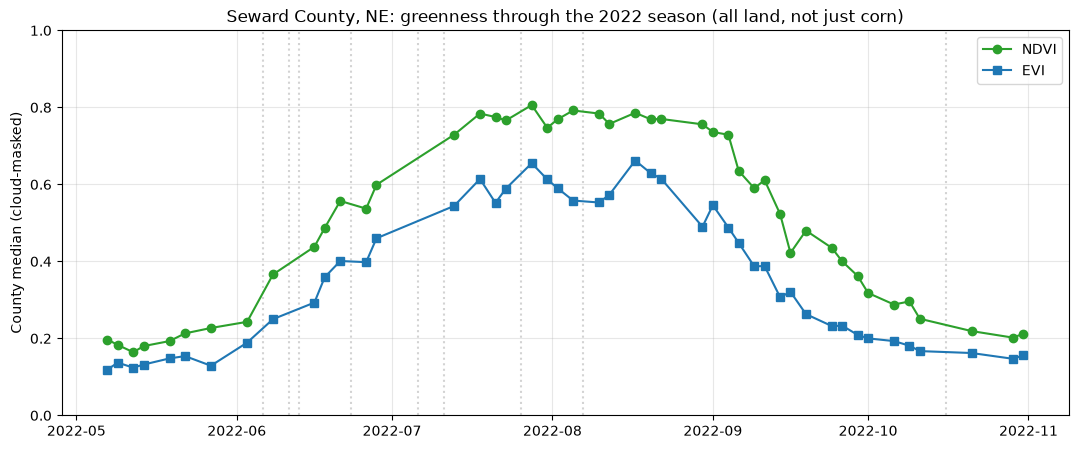

NDVI peak: 2022-07-28 → 0.806


In [4]:
used = ts.dropna(subset=["ndvi"])          # only dates with values
skipped = ts[ts["ndvi"].isna()]            # the too-cloudy dates

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(used["date"], used["ndvi"], "o-", color="tab:green", label="NDVI")
ax.plot(used["date"], used["evi"],  "s-", color="tab:blue",  label="EVI")

for d in skipped["date"]:                  # mark cloudy (skipped) dates
    ax.axvline(d, color="lightgrey", linestyle=":", zorder=0)

ax.set_ylim(0, 1)
ax.set_ylabel("County median (cloud-masked)")
ax.set_title("Seward County, NE: greenness through the 2022 season (all land, not just corn)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# When was the peak?
peak = used.loc[used["ndvi"].idxmax()]
print("NDVI peak:", peak["date"].date(), "→", peak["ndvi"])

In [5]:
from pathlib import Path

# Find the project folder (the one that has pyproject.toml)
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent

# Save the table as a CSV file in results/
csv_path = root / "results" / "seward_2022_ndvi_evi_timeseries.csv"
ts.to_csv(csv_path, index=False)
print("Saved:", csv_path)

# Read it back to check it saved correctly
check = pd.read_csv(csv_path, parse_dates=["date"])
print("Rows:", len(check), "| used dates:", check["ndvi"].notna().sum())
check.head()

Saved: /Users/iffat180/Desktop/AgroScope/results/seward_2022_ndvi_evi_timeseries.csv
Rows: 55 | used dates: 46


,date,item,clear,ndvi,evi
0,2022-05-07,S2A_14TPL_20220507_0_L2A,0.561,0.197,0.119
1,2022-05-09,S2B_14TPL_20220509_0_L2A,0.999,0.183,0.137
2,2022-05-12,S2B_14TPL_20220512_0_L2A,0.622,0.164,0.124
3,2022-05-14,S2A_14TPL_20220514_0_L2A,0.782,0.180,0.132
4,2022-05-19,S2B_14TPL_20220519_0_L2A,0.765,0.193,0.148
